<hr style="border: 2px solid #7C6F64; margin-top: 10px;">

# Underwater Segmentation - timm DINO Semantic Decoder

Template khusus kompetisi segmentasi bawah laut 8 kelas. Output submission mengikuti `sample_submission.csv`: `id,BW,HD,PF,WR,RO,RI,FV,SR` dengan RLE column-major 1-index.


## Catatan Model

Notebook ini memakai backbone DINO dari timm sebagai frozen/finetuned encoder lalu menambahkan decoder semantic segmentation 8 kelas. Default memakai DINOv2 publik dari timm supaya tidak perlu login Hugging Face atau akses repo gated. Untuk dataset kecil 1.525 gambar, default `freeze_backbone=True` mengurangi risiko overfit dan hemat VRAM.


## Instalasi Modul


In [1]:
# %pip install -q -U timm accelerate scikit-learn matplotlib seaborn pillow opencv-python tqdm


## Pustaka


In [2]:
import os, re, random, warnings, math, csv
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")


## Seed


In [3]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed_everything(42)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0), torch.cuda.get_device_capability(0))


Device: cuda
Tesla T4 (7, 5)


## Settings / Config


In [4]:
class Settings:
    SEED = 42
    RUN_NAME = "underwater_segmentation_timm_dino"

    # Ubah 4 path ini sesuai environment: local, Kaggle, atau Colab.
    DATA_ROOT = Path("/kaggle/input/competitions/internal-gemastik-xix-itb-image-segmentation")
    TRAIN_PATH = DATA_ROOT / "train"
    TEST_PATH = DATA_ROOT / "test"
    OUTPUT_PATH = Path("/kaggle/working") if Path("/kaggle/working").exists() else DATA_ROOT / "outputs"
    SAMPLE_SUBMISSION_PATH = DATA_ROOT / "sample_submission.csv"

    TRAIN_IMAGE_DIR = TRAIN_PATH / "images"
    TRAIN_MASK_DIR = TRAIN_PATH / "masks"
    TEST_IMAGE_DIR = TEST_PATH / "images"

    MODEL_REGISTRY = {
        "dinov2_base_timm": {
            "model_id": "vit_base_patch14_dinov2.lvd142m",
            "patch_size": 14,
            "img_size": (518, 518),
            "batch_size": 4,
            "lr": 2e-4,
            "pretrained": True,
            "freeze_backbone": True,
            "description": "DINOv2 ViT-B/14 dari timm, publik dan tidak perlu HF login.",
            "when_to_use": "Default stabil tanpa akses gated; fitur kuat untuk dataset kecil-menengah.",
        },
        "dinov2_small_timm": {
            "model_id": "vit_small_patch14_dinov2.lvd142m",
            "patch_size": 14,
            "img_size": (518, 518),
            "batch_size": 8,
            "lr": 3e-4,
            "pretrained": True,
            "freeze_backbone": True,
            "description": "DINOv2 ViT-S/14 dari timm, lebih ringan dan cepat.",
            "when_to_use": "Pakai kalau VRAM terbatas atau ingin iterasi cepat.",
        },
        "dinov2_large_timm": {
            "model_id": "vit_large_patch14_dinov2.lvd142m",
            "patch_size": 14,
            "img_size": (518, 518),
            "batch_size": 2,
            "lr": 1e-4,
            "pretrained": True,
            "freeze_backbone": True,
            "description": "DINOv2 ViT-L/14 dari timm, lebih kuat tapi lebih berat.",
            "when_to_use": "Pakai jika base underfit dan GPU cukup.",
        },
    }
    MODEL_NAME = "dinov2_base_timm"
    MODEL_CONFIG = MODEL_REGISTRY[MODEL_NAME]
    MODEL_ID = MODEL_CONFIG["model_id"]
    OUTPUT_DIR = OUTPUT_PATH / f"{RUN_NAME}_{MODEL_NAME}"

    NUM_CLASSES = 8
    IMG_SIZE = MODEL_CONFIG["img_size"]
    PATCH_SIZE = MODEL_CONFIG["patch_size"]
    BATCH_SIZE = MODEL_CONFIG["batch_size"]
    NUM_WORKERS = 2
    EPOCHS = 20
    LR = MODEL_CONFIG["lr"]
    WEIGHT_DECAY = 1e-4
    GRAD_CLIP = 1.0
    USE_AMP = True
    VAL_SIZE = 0.15
    EARLY_STOP_PATIENCE = 5
    CE_WEIGHT = 0.6
    DICE_WEIGHT = 0.4
    IMAGENET_MEAN = [0.485, 0.456, 0.406]
    IMAGENET_STD = [0.229, 0.224, 0.225]


CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(CFG.SEED)
model_catalog_df = pd.DataFrame.from_dict(CFG.MODEL_REGISTRY, orient="index")
display(model_catalog_df[["model_id", "description", "when_to_use", "img_size", "batch_size", "lr"]])
print("Selected model:", CFG.MODEL_NAME, CFG.MODEL_ID)
print("Output dir:", CFG.OUTPUT_DIR)


,model_id,description,when_to_use,img_size,batch_size,lr
dinov2_base_timm,vit_base_patch14_dinov2.lvd142m,"DINOv2 ViT-B/14 dari timm, publik dan tidak pe...",Default stabil tanpa akses gated; fitur kuat u...,"(518, 518)",4,0.0002
dinov2_small_timm,vit_small_patch14_dinov2.lvd142m,"DINOv2 ViT-S/14 dari timm, lebih ringan dan ce...",Pakai kalau VRAM terbatas atau ingin iterasi c...,"(518, 518)",8,0.0003
dinov2_large_timm,vit_large_patch14_dinov2.lvd142m,"DINOv2 ViT-L/14 dari timm, lebih kuat tapi leb...",Pakai jika base underfit dan GPU cukup.,"(518, 518)",2,0.0001


Selected model: dinov2_base_timm vit_base_patch14_dinov2.lvd142m
Output dir: /kaggle/working/underwater_segmentation_timm_dino_dinov2_base_timm


## Utilitas Dataset, Mask, Metric, RLE


In [5]:
CLASS_NAMES = ["BW", "HD", "PF", "WR", "RO", "RI", "FV", "SR"]
CLASS_DESCRIPTIONS = {
    "BW": "Latar belakang / badan air",
    "HD": "Penyelam manusia",
    "PF": "Tanaman air dan rumput laut",
    "WR": "Bangkai kapal dan reruntuhan",
    "RO": "Robot / AUV / ROV / instrumen",
    "RI": "Terumbu karang dan invertebrata",
    "FV": "Ikan dan vertebrata",
    "SR": "Dasar laut dan bebatuan",
}
CLASS_COLORS = {
    "BW": (0, 0, 0),
    "HD": (0, 0, 255),
    "PF": (0, 255, 0),
    "WR": (0, 255, 255),
    "RO": (255, 0, 0),
    "RI": (255, 0, 255),
    "FV": (255, 255, 0),
    "SR": (255, 255, 255),
}
ID2LABEL = {i: name for i, name in enumerate(CLASS_NAMES)}
LABEL2ID = {name: i for i, name in ID2LABEL.items()}

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def list_images(root_dir):
    root_dir = Path(root_dir)
    return sorted([p for p in root_dir.rglob("*") if p.suffix.lower() in IMAGE_SUFFIXES], key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem)


def load_rgb(path):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img)
    return img.convert("RGB")


def rgb_mask_to_class(mask_img):
    arr = np.array(mask_img.convert("RGB"))
    bits = (arr > 127).astype(np.uint8)
    return (bits[..., 0] * 4 + bits[..., 1] * 2 + bits[..., 2]).astype(np.uint8)


def class_map_to_rgb(class_map):
    out = np.zeros((*class_map.shape, 3), dtype=np.uint8)
    for idx, name in ID2LABEL.items():
        out[class_map == idx] = CLASS_COLORS[name]
    return out


def extract_id(path):
    return int(Path(path).stem) if Path(path).stem.isdigit() else Path(path).stem


def build_pairs(image_dir, mask_dir):
    image_paths = list_images(image_dir)
    mask_map = {p.stem: p for p in list_images(mask_dir)}
    pairs, missing = [], []
    for img_path in image_paths:
        mask_path = mask_map.get(img_path.stem)
        if mask_path is None:
            missing.append(img_path)
        else:
            pairs.append((img_path, mask_path))
    if missing:
        print("Missing masks:", len(missing), missing[:5])
    return pairs


def mask_to_rle(mask):
    mask = mask.astype(np.uint8)
    pixels = mask.T.flatten()  # column-major
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(str(x) for x in runs)


def mean_dice_competition(pred, true, num_classes=8):
    scores = []
    for cls in range(num_classes):
        p = pred == cls
        g = true == cls
        ps, gs = p.sum(), g.sum()
        if ps == 0 and gs == 0:
            continue
        if ps == 0 or gs == 0:
            scores.append(0.0)
        else:
            inter = np.logical_and(p, g).sum()
            scores.append(2 * inter / (ps + gs))
    return np.nan if not scores else float(np.mean(scores))


def overlay_mask(image, class_map, alpha=0.45):
    img = np.array(image).copy().astype(np.float32)
    color = class_map_to_rgb(class_map).astype(np.float32)
    return np.clip(img * (1 - alpha) + color * alpha, 0, 255).astype(np.uint8)


## Load Data dan EDA


train pairs: 1525
test images : 110
sample_submission: (110, 9)


,id,BW,HD,PF,WR,RO,RI,FV,SR
0,1,,,,,,,,
1,2,,,,,,,,
2,3,,,,,,,,
3,4,,,,,,,,
4,5,,,,,,,,


inspect subset:   0%|          | 0/400 [00:00<?, ?it/s]

,id,img_w,img_h,mask_w,mask_h,same_size
count,400.000000,400.000000,400.000000,400.000000,400.000000,400
unique,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,True
freq,NaN,NaN,NaN,NaN,NaN,394
mean,200.500000,725.500000,505.855000,725.500000,506.680000,NaN
std,115.614301,219.161011,90.424418,219.161011,89.470274,NaN
min,1.000000,480.000000,360.000000,480.000000,360.000000,NaN
25%,100.750000,640.000000,480.000000,640.000000,480.000000,NaN
50%,200.500000,640.000000,480.000000,640.000000,480.000000,NaN
75%,300.250000,640.000000,480.000000,640.000000,480.000000,NaN


,presence_subset,pixels_subset
BW,334,49733586
HD,165,5278680
PF,53,3629844
WR,168,23619925
RO,43,1702585
RI,201,36195817
FV,171,7179965
SR,198,27130438


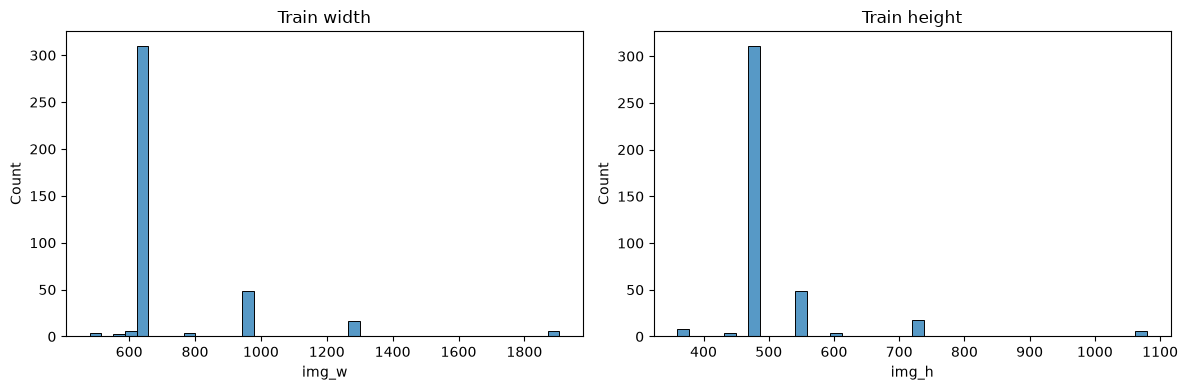

In [6]:
train_pairs = build_pairs(CFG.TRAIN_IMAGE_DIR, CFG.TRAIN_MASK_DIR)
test_images = list_images(CFG.TEST_IMAGE_DIR)
sample_submission = pd.read_csv(CFG.SAMPLE_SUBMISSION_PATH)
print("train pairs:", len(train_pairs))
print("test images :", len(test_images))
print("sample_submission:", sample_submission.shape)
display(sample_submission.head())

rows = []
class_presence = Counter()
class_pixels = Counter()
for img_path, mask_path in tqdm(train_pairs[:400], desc="inspect subset"):
    img = load_rgb(img_path)
    mask_img = load_rgb(mask_path)
    cls_map = rgb_mask_to_class(mask_img)
    rows.append({"id": extract_id(img_path), "img_w": img.width, "img_h": img.height, "mask_w": mask_img.width, "mask_h": mask_img.height, "same_size": img.size == mask_img.size})
    for cls_idx, cls_name in ID2LABEL.items():
        n = int((cls_map == cls_idx).sum())
        if n > 0:
            class_presence[cls_name] += 1
            class_pixels[cls_name] += n
meta_df = pd.DataFrame(rows)
display(meta_df.describe(include="all"))
display(pd.DataFrame({"presence_subset": class_presence, "pixels_subset": class_pixels}).fillna(0).astype(int).reindex(CLASS_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(meta_df["img_w"], ax=axes[0])
axes[0].set_title("Train width")
sns.histplot(meta_df["img_h"], ax=axes[1])
axes[1].set_title("Train height")
plt.tight_layout()
plt.show()


## Visualisasi Sampel


ValueError: operands could not be broadcast together with shapes (375,590,3) (430,590,3) 

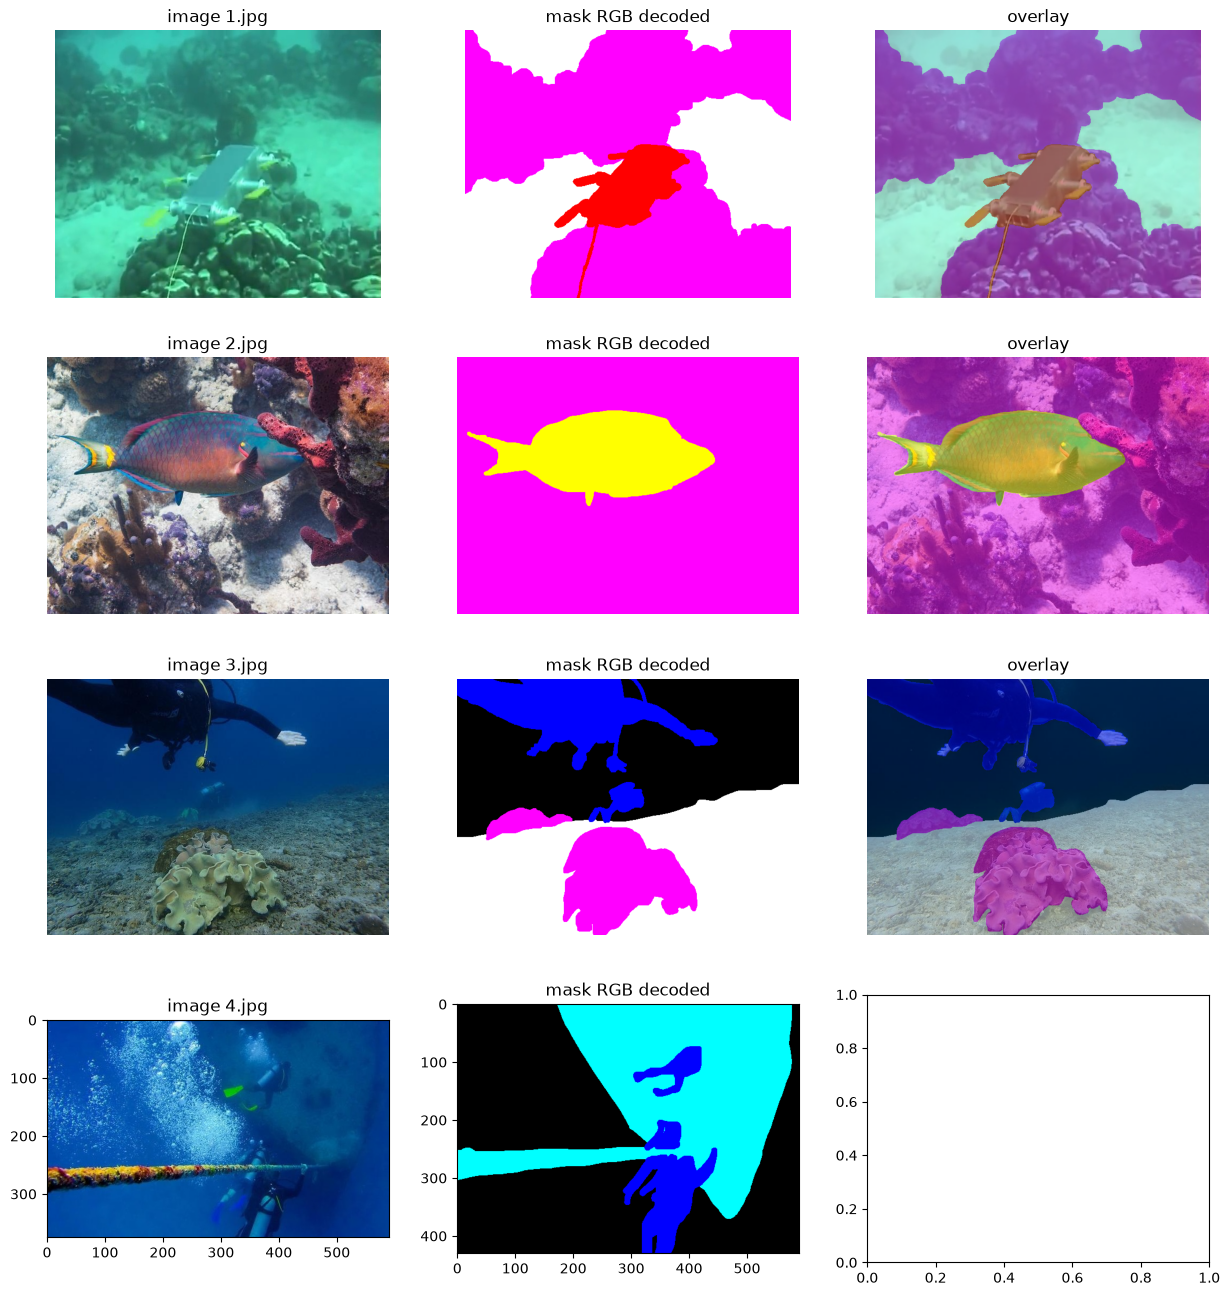

In [7]:
# def show_samples(pairs, n=4):
#     sample = pairs[:n]
#     fig, axes = plt.subplots(len(sample), 3, figsize=(15, 4 * len(sample)))
#     axes = np.array(axes).reshape(len(sample), 3)
#     for i, (img_path, mask_path) in enumerate(sample):
#         img = load_rgb(img_path)
#         cls_map = rgb_mask_to_class(load_rgb(mask_path))
#         axes[i, 0].imshow(img)
#         axes[i, 0].set_title(f"image {img_path.name}")
#         axes[i, 1].imshow(class_map_to_rgb(cls_map))
#         axes[i, 1].set_title("mask RGB decoded")
#         axes[i, 2].imshow(overlay_mask(img, cls_map))
#         axes[i, 2].set_title("overlay")
#         for ax in axes[i]:
#             ax.axis("off")
#     plt.tight_layout()
#     plt.show()

# show_samples(train_pairs, n=min(4, len(train_pairs)))


## Dataset dan DataLoader


In [8]:
def resize_image_and_mask(image, mask=None, size=(512, 512), train=False):
    image = image.resize((size[1], size[0]), Image.Resampling.BILINEAR)
    if mask is not None:
        mask = Image.fromarray(mask.astype(np.uint8)).resize((size[1], size[0]), Image.Resampling.NEAREST)
        mask = np.array(mask).astype(np.int64)
    if train and random.random() < 0.5:
        image = ImageOps.mirror(image)
        if mask is not None:
            mask = np.ascontiguousarray(mask[:, ::-1])
    return image, mask


class UnderwaterSegmentationDataset(Dataset):
    def __init__(self, items, img_size, train=False, has_mask=True, image_mean=None, image_std=None):
        self.items = list(items)
        self.img_size = tuple(img_size)
        self.train = train
        self.has_mask = has_mask
        self.mean = torch.tensor(image_mean or [0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std = torch.tensor(image_std or [0.229, 0.224, 0.225]).view(3, 1, 1)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        if self.has_mask:
            img_path, mask_path = self.items[idx]
        else:
            img_path, mask_path = self.items[idx], None
        image = load_rgb(img_path)
        original_size = image.size  # (w, h)
        mask = rgb_mask_to_class(load_rgb(mask_path)) if mask_path is not None else None
        image, mask = resize_image_and_mask(image, mask, self.img_size, train=self.train)
        arr = np.array(image).astype(np.float32) / 255.0
        x = torch.from_numpy(arr).permute(2, 0, 1)
        x = (x - self.mean) / self.std
        item = {"image": x, "path": str(img_path), "id": extract_id(img_path), "original_size": torch.tensor(original_size, dtype=torch.long)}
        if mask is not None:
            item["mask"] = torch.from_numpy(mask).long()
        return item


def split_train_val(pairs):
    ids = [extract_id(p[0]) for p in pairs]
    tr, va = train_test_split(pairs, test_size=CFG.VAL_SIZE, random_state=CFG.SEED)
    return tr, va


tr_pairs, va_pairs = split_train_val(train_pairs)
train_loader = DataLoader(UnderwaterSegmentationDataset(tr_pairs, CFG.IMG_SIZE, train=True, image_mean=CFG.IMAGENET_MEAN, image_std=CFG.IMAGENET_STD), batch_size=CFG.BATCH_SIZE, shuffle=True, num_workers=CFG.NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(UnderwaterSegmentationDataset(va_pairs, CFG.IMG_SIZE, train=False, image_mean=CFG.IMAGENET_MEAN, image_std=CFG.IMAGENET_STD), batch_size=CFG.BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(UnderwaterSegmentationDataset(test_images, CFG.IMG_SIZE, train=False, has_mask=False, image_mean=CFG.IMAGENET_MEAN, image_std=CFG.IMAGENET_STD), batch_size=CFG.BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)
print(len(tr_pairs), len(va_pairs), len(test_images))


1296 229 110


## Model timm DINO Semantic Segmenter


In [9]:
class TimmDinoSemanticSegmenter(nn.Module):
    def __init__(self, model_name, num_classes, pretrained=True, freeze_backbone=True):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool="")
        hidden = self.backbone.num_features
        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False
        self.decoder = nn.Sequential(
            nn.Conv2d(hidden, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.GELU(),
            nn.Conv2d(512, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.GELU(),
            nn.Conv2d(256, num_classes, kernel_size=1),
        )

    def _tokens_to_feature_map(self, tokens, x):
        h = x.shape[-2] // CFG.PATCH_SIZE
        w = x.shape[-1] // CFG.PATCH_SIZE
        n = h * w
        patch_tokens = tokens[:, -n:, :]
        return patch_tokens.transpose(1, 2).reshape(x.size(0), -1, h, w)

    def forward(self, x):
        feat = self.backbone.forward_features(x)
        if isinstance(feat, dict):
            if "x_norm_patchtokens" in feat:
                feat = feat["x_norm_patchtokens"]
            elif "tokens" in feat:
                feat = feat["tokens"]
            else:
                feat = next(v for v in feat.values() if torch.is_tensor(v))
        if isinstance(feat, (list, tuple)):
            feat = feat[-1]
        if feat.ndim == 3:
            feat = self._tokens_to_feature_map(feat, x)
        elif feat.ndim == 4 and feat.shape[1] != self.backbone.num_features:
            feat = feat.permute(0, 3, 1, 2).contiguous()
        logits = self.decoder(feat)
        return F.interpolate(logits, size=x.shape[-2:], mode="bilinear", align_corners=False)


model = TimmDinoSemanticSegmenter(
    CFG.MODEL_ID,
    CFG.NUM_CLASSES,
    pretrained=CFG.MODEL_CONFIG.get("pretrained", True),
    freeze_backbone=CFG.MODEL_CONFIG.get("freeze_backbone", True),
).to(DEVICE)
print("parameters:", sum(p.numel() for p in model.parameters()) / 1e6, "M")
print("trainable:", sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, "M")


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

parameters: 91.302664 M
trainable: 4.722952 M


## Training Utilities


In [10]:
def multiclass_dice_loss(logits, target, num_classes=8, eps=1e-7):
    probs = torch.softmax(logits, dim=1)
    onehot = F.one_hot(target.clamp(0, num_classes - 1), num_classes).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)
    inter = torch.sum(probs * onehot, dims)
    union = torch.sum(probs + onehot, dims)
    dice = (2 * inter + eps) / (union + eps)
    return 1 - dice.mean()


def competition_metric_from_logits(logits, target):
    pred = logits.argmax(dim=1).detach().cpu().numpy()
    true = target.detach().cpu().numpy()
    scores = [mean_dice_competition(p, g, CFG.NUM_CLASSES) for p, g in zip(pred, true)]
    return float(np.nanmean(scores)) if scores else 0.0


def run_epoch(model, loader, optimizer=None, scaler=None):
    is_train = optimizer is not None
    model.train(is_train)
    ce = nn.CrossEntropyLoss()
    total_loss, scores = 0.0, []
    pbar = tqdm(loader, desc="train" if is_train else "valid", leave=False)
    for batch in pbar:
        x = batch["image"].to(DEVICE)
        y = batch["mask"].to(DEVICE)
        with torch.set_grad_enabled(is_train):
            with torch.cuda.amp.autocast(enabled=CFG.USE_AMP and DEVICE.type == "cuda"):
                logits = model(x)
                loss = CFG.CE_WEIGHT * ce(logits, y) + CFG.DICE_WEIGHT * multiclass_dice_loss(logits, y, CFG.NUM_CLASSES)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                if scaler is not None and CFG.USE_AMP:
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
                    optimizer.step()
        total_loss += loss.item() * x.size(0)
        scores.append(competition_metric_from_logits(logits, y))
        pbar.set_postfix(loss=loss.item(), dice=np.mean(scores))
    return {"loss": total_loss / max(len(loader.dataset), 1), "mean_dice": float(np.mean(scores))}


def fit_model(model, train_loader, val_loader):
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS)
    scaler = torch.cuda.amp.GradScaler(enabled=CFG.USE_AMP and DEVICE.type == "cuda")
    best_score, bad_epochs, history = -1, 0, []
    for epoch in range(1, CFG.EPOCHS + 1):
        train_log = run_epoch(model, train_loader, optimizer, scaler)
        val_log = run_epoch(model, val_loader)
        scheduler.step()
        row = {"epoch": epoch, **{f"train_{k}": v for k, v in train_log.items()}, **{f"val_{k}": v for k, v in val_log.items()}}
        history.append(row)
        print(row)
        if val_log["mean_dice"] > best_score:
            best_score = val_log["mean_dice"]
            bad_epochs = 0
            torch.save({"model": model.state_dict(), "cfg": CFG.__dict__, "score": best_score}, CFG.OUTPUT_DIR / "best_model.pt")
            print("Saved best:", best_score)
        else:
            bad_epochs += 1
            if bad_epochs >= CFG.EARLY_STOP_PATIENCE:
                print("Early stopping")
                break
    return pd.DataFrame(history)


## Train


In [ ]:
history_df = fit_model(model, train_loader, val_loader)
history_df.tail()


train:   0%|          | 0/324 [00:00<?, ?it/s]

## Post-Train Analysis


In [ ]:
history_df.to_csv(CFG.OUTPUT_DIR / "history.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "mean_dice"]):
    ax.plot(history_df["epoch"], history_df[f"train_{metric}"], label="train")
    ax.plot(history_df["epoch"], history_df[f"val_{metric}"], label="val")
    ax.set_title(metric)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


## Inference dan Submission


In [ ]:
@torch.no_grad()
def predict_test(model, loader):
    model.eval()
    rows = []

    pred_dir = (
        CFG.OUTPUT_DIR
        / "pred_masks_rgb"
    )
    pred_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    for batch in tqdm(
        loader,
        desc="predict",
    ):
        x = batch["image"].to(
            DEVICE
        )
        logits = model(x)

        pred = (
            logits.argmax(dim=1)
            .detach()
            .cpu()
            .numpy()
            .astype(np.uint8)
        )

        for (
            img_id,
            path,
            class_map,
            original_size,
        ) in zip(
            batch["id"].cpu().numpy(),
            batch["path"],
            pred,
            batch["original_size"]
            .cpu()
            .numpy(),
        ):
            width, height = map(
                int,
                original_size,
            )

            resized = Image.fromarray(
                class_map
            ).resize(
                (width, height),
                Image.Resampling.NEAREST,
            )

            class_original = np.asarray(
                resized,
                dtype=np.uint8,
            )

            Image.fromarray(
                class_map_to_rgb(
                    class_original
                )
            ).save(
                pred_dir
                / f"{Path(path).stem}.png"
            )

            row = {
                "id": int(img_id)
            }

            for class_id, class_name in (
                ID2LABEL.items()
            ):
                row[class_name] = (
                    mask_to_rle(
                        class_original
                        == class_id
                    )
                )

            rows.append(row)

    return pd.DataFrame(rows)


def validate_rle_string(value):
    """
    RLE valid:
    - string kosong/whitespace berarti tidak ada run;
    - token harus berpasangan: start length;
    - start dan length harus integer positif.
    """
    if value is None:
        return True

    text = str(value).strip()

    if text == "":
        return True

    tokens = text.split()

    if len(tokens) % 2 != 0:
        return False

    try:
        numbers = [
            int(token)
            for token in tokens
        ]
    except ValueError:
        return False

    starts = numbers[0::2]
    lengths = numbers[1::2]

    return (
        all(start >= 1 for start in starts)
        and all(length >= 1 for length in lengths)
    )


def write_kaggle_submission(
    submission_df,
    output_path,
):
    """
    Mengubah DataFrame submission menjadi CSV Kaggle-ready.

    Format:
    id,BW,HD,PF,WR,RO,RI,FV,SR

    Kategori tanpa prediksi ditulis sebagai satu whitespace terkutip:
    " "

    Hal ini tetap bermakna tidak ada run, tetapi mencegah parser
    membaca field tersebut sebagai null/NaN.
    """
    expected_columns = [
        "id",
        *CLASS_NAMES,
    ]

    submission_df = (
        submission_df.copy()
    )

    if (
        submission_df.columns.tolist()
        != expected_columns
    ):
        raise ValueError(
            "Kolom submission tidak sesuai.\n"
            f"Ditemukan : "
            f"{submission_df.columns.tolist()}\n"
            f"Diharapkan: "
            f"{expected_columns}"
        )

    submission_df["id"] = (
        submission_df["id"]
        .astype(str)
        .str.strip()
    )

    if (
        submission_df["id"]
        .eq("")
        .any()
    ):
        raise ValueError(
            "Terdapat ID kosong."
        )

    if (
        submission_df["id"]
        .duplicated()
        .any()
    ):
        duplicate_ids = (
            submission_df.loc[
                submission_df["id"]
                .duplicated(keep=False),
                "id",
            ]
            .tolist()
        )

        raise ValueError(
            "Terdapat ID duplikat: "
            f"{duplicate_ids[:20]}"
        )

    for column in CLASS_NAMES:
        cleaned_values = []

        for row_id, value in zip(
            submission_df["id"],
            submission_df[column],
        ):
            if (
                value is None
                or pd.isna(value)
                or str(value).strip().lower()
                in {
                    "",
                    "nan",
                    "none",
                    "null",
                    "<na>",
                    "na",
                }
            ):
                # Non-null placeholder yang tetap berarti tidak ada run.
                cleaned_values.append(
                    " "
                )
                continue

            normalized = " ".join(
                str(value).split()
            )

            if not validate_rle_string(
                normalized
            ):
                raise ValueError(
                    "RLE tidak valid pada "
                    f"id={row_id}, "
                    f"kolom={column}: "
                    f"{normalized[:150]}"
                )

            cleaned_values.append(
                normalized
            )

        submission_df[column] = (
            cleaned_values
        )

    output_path = Path(
        output_path
    )
    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    # Header ditulis persis seperti format kompetisi.
    # Semua field data dikutip agar whitespace placeholder dipertahankan.
    with output_path.open(
        "w",
        encoding="utf-8",
        newline="",
    ) as handle:
        handle.write(
            ",".join(expected_columns)
            + "\n"
        )

        writer = csv.writer(
            handle,
            quoting=csv.QUOTE_ALL,
            lineterminator="\n",
        )

        for row in submission_df[
            expected_columns
        ].itertuples(
            index=False,
            name=None,
        ):
            writer.writerow(row)

    # Baca ulang dengan parser default.
    # Tidak boleh ada null/NaN setelah file tersimpan.
    checked_default = pd.read_csv(
        output_path,
        dtype=str,
    )

    if (
        checked_default.isna()
        .any()
        .any()
    ):
        null_locations = (
            checked_default.isna()
            .stack()
        )
        null_locations = (
            null_locations[
                null_locations
            ]
            .index
            .tolist()
        )

        raise AssertionError(
            "CSV masih mengandung null: "
            f"{null_locations[:20]}"
        )

    checked = pd.read_csv(
        output_path,
        dtype=str,
        keep_default_na=False,
    )

    if (
        checked.columns.tolist()
        != expected_columns
    ):
        raise AssertionError(
            "Header berubah setelah ekspor."
        )

    if (
        len(checked)
        != len(submission_df)
    ):
        raise AssertionError(
            "Jumlah baris berubah "
            "setelah ekspor."
        )

    for column in CLASS_NAMES:
        if not checked[column].map(
            validate_rle_string
        ).all():
            raise AssertionError(
                f"RLE invalid pada kolom "
                f"{column} setelah ekspor."
            )

    print(
        "Kaggle-ready submission:",
        output_path,
    )
    print(
        "Rows:",
        len(checked),
    )
    print(
        "Columns:",
        checked.columns.tolist(),
    )
    print(
        "Null values:",
        int(
            checked_default.isna()
            .sum()
            .sum()
        ),
    )

    return checked


# ============================================================
# Prediksi test
# ============================================================

checkpoint = torch.load(
    CFG.OUTPUT_DIR
    / "best_model.pt",
    map_location=DEVICE,
)

model.load_state_dict(
    checkpoint["model"]
)

test_pred_df = predict_test(
    model,
    test_loader,
)

# Simpan hasil prediksi mentah untuk audit/debugging.
test_pred_df.to_csv(
    CFG.OUTPUT_DIR
    / "test_predictions_full.csv",
    index=False,
)


# ============================================================
# Susun urutan submission mengikuti sample_submission.csv
# ============================================================

submission = (
    sample_submission[["id"]]
    .merge(
        test_pred_df,
        on="id",
        how="left",
        sort=False,
        validate="one_to_one",
    )
)

submission = submission[
    ["id", *CLASS_NAMES]
]


# ============================================================
# Konversi otomatis ke format Kaggle yang diterima
# ============================================================

submission_path = (
    CFG.OUTPUT_DIR
    / "submission.csv"
)

submission_checked = (
    write_kaggle_submission(
        submission,
        submission_path,
    )
)

display(
    submission_checked.head()
)

## Format output submission

Cell terakhir otomatis menghasilkan:

```text
submission.csv
```

dengan header:

```text
id,BW,HD,PF,WR,RO,RI,FV,SR
```

RLE tetap column-major dan 1-indexed. Kategori tanpa prediksi dikonversi menjadi whitespace terkutip (`" "`) agar tidak terbaca sebagai `null/NaN` oleh validator submission.